In [1]:
print("COD Risk Management Project Started!")

COD Risk Management Project Started!


In [7]:
import pandas as pd

df = pd.read_csv("../data/copy of orders_sample.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (2018, 17)


In [8]:
# Display first 5 rows
display(df.head())

# Check all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate order IDs
print("\nDuplicate Order IDs:")
print(df["order_id"].duplicated().sum())

# Check order status distribution
print("\nOrder Status:")
print(df["final_status"].value_counts())

,order_id,order_datetime,customer_name,phone,address,city,state,pincode,order_value,items,num_items,customer_prior_orders,customer_prior_rto,utm_source,courier,payment_method,final_status
0,KT100193,2026-06-18 15:34,Lakshmi Shaikh,6007018646,"Station chowk se left, Hanuman Mandir ke saamne",Chennai,Tamil Nadu,600084.0,349,Satin Pillowcase,1,0,0,meta_ads,Delhivery,COD,DELIVERED
1,KT101714,2026-07-26 09:36,Tanvi Das,9895118261,"Link chowk se left, SBI Bank ke saamne",Indore,Madhya Pradesh,452026.0,898,Rice Water Shampoo Bar|Satin Bonnet,2,0,0,meta_ads,BlueDart,COD,DELIVERED
2,KT100452,2026-05-29 22:37,Swati Das,9583831354,"399/13, Station Nagar, Opp. Railway Crossing",Chennai,Tamil Nadu,600092.0,449,Satin Pillowcase,1,0,0,meta_ads,Delhivery,COD,DELIVERED
3,KT101753,2026-06-29 12:46,Meera Pillai,9109605378,"784/17, MG Nagar, Opp. Hanuman Mandir",Lucknow,Uttar Pradesh,226036.0,699,Satin Bonnet,1,0,0,direct,Xpressbees,COD,RTO
4,KT100195,2026-05-13 14:15,Sneha Reddy,6763180097,"ph krke aana, Govt School ke paas",Hyderabad,Telangana,500058.0,499,Claw Clip Set,1,0,0,meta_ads,Xpressbees,COD,DELIVERED



Column Names:
['order_id', 'order_datetime', 'customer_name', 'phone', 'address', 'city', 'state', 'pincode', 'order_value', 'items', 'num_items', 'customer_prior_orders', 'customer_prior_rto', 'utm_source', 'courier', 'payment_method', 'final_status']

Data Types:
order_id                     str
order_datetime               str
customer_name                str
phone                        str
address                      str
city                         str
state                        str
pincode                  float64
order_value                int64
items                        str
num_items                  int64
customer_prior_orders      int64
customer_prior_rto         int64
utm_source                   str
courier                      str
payment_method               str
final_status                 str
dtype: object

Missing Values:
order_id                  0
order_datetime            0
customer_name             0
phone                     0
address                   0
c

In [9]:
# Check duplicate order IDs
print("Duplicate order IDs:",
      df["order_id"].duplicated().sum())

# Check delivery status
print("\nStatus distribution:")
print(df["final_status"].value_counts(dropna=False))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Duplicate order IDs: 30

Status distribution:
final_status
DELIVERED     1443
RTO            570
Rto              2
delivered        1
RTO              1
IN_TRANSIT       1
Name: count, dtype: int64

Missing values:
order_id                  0
order_datetime            0
customer_name             0
phone                     0
address                   0
city                      4
state                     0
pincode                  12
order_value               0
items                     0
num_items                 0
customer_prior_orders     0
customer_prior_rto        0
utm_source                0
courier                   0
payment_method            0
final_status              0
dtype: int64


In [10]:
# Make a copy of original data
df_clean = df.copy()

# Standardize status values
df_clean["final_status"] = (
    df_clean["final_status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Remove duplicate order IDs
df_clean = df_clean.drop_duplicates(
    subset=["order_id"],
    keep="first"
)

# Keep only completed delivery outcomes
df_clean = df_clean[
    df_clean["final_status"].isin(["DELIVERED", "RTO"])
].copy()

# Create target column
df_clean["is_rto"] = (
    df_clean["final_status"] == "RTO"
).astype(int)

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))
print("\nTarget distribution:")
print(df_clean["is_rto"].value_counts())

Original rows: 2018
Clean rows: 1987

Target distribution:
is_rto
0    1422
1     565
Name: count, dtype: int64


In [11]:
total_orders = len(df_clean)

rto_orders = df_clean["is_rto"].sum()

delivered_orders = total_orders - rto_orders

rto_percentage = (rto_orders / total_orders) * 100

delivery_percentage = (
    delivered_orders / total_orders
) * 100

print("Total Orders:", total_orders)
print("RTO Orders:", rto_orders)
print("Delivered Orders:", delivered_orders)

print(f"RTO Rate: {rto_percentage:.2f}%")
print(f"Delivery Rate: {delivery_percentage:.2f}%")

Total Orders: 1987
RTO Orders: 565
Delivered Orders: 1422
RTO Rate: 28.43%
Delivery Rate: 71.57%


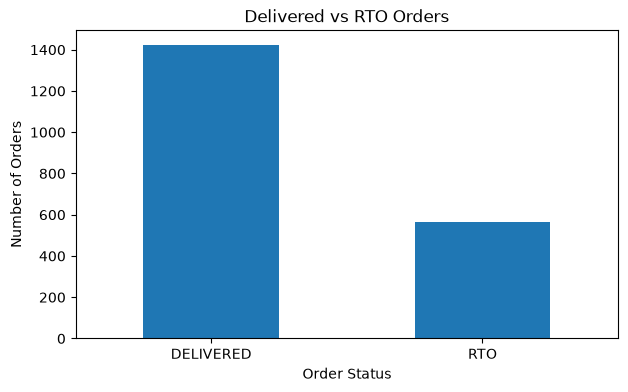

In [12]:
import matplotlib.pyplot as plt

status_counts = df_clean["final_status"].value_counts()

status_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Delivered vs RTO Orders"
)

plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()

In [13]:
customer_analysis = df_clean.copy()

customer_analysis["customer_type"] = customer_analysis[
    "customer_prior_orders"
].apply(
    lambda x: "First-time" if x == 0 else "Repeat"
)

customer_stats = customer_analysis.groupby(
    "customer_type"
).agg(
    total_orders=("is_rto", "count"),
    rto_orders=("is_rto", "sum"),
    rto_rate=("is_rto", "mean")
)

customer_stats["rto_rate"] *= 100

print(customer_stats.round(2))

               total_orders  rto_orders  rto_rate
customer_type                                    
First-time             1495         452     30.23
Repeat                  492         113     22.97


In [14]:
source_analysis = df_clean.groupby("utm_source").agg(
    total_orders=("is_rto", "count"),
    rto_orders=("is_rto", "sum"),
    rto_rate=("is_rto", "mean")
)

source_analysis["rto_rate"] *= 100

source_analysis = source_analysis.sort_values(
    "rto_rate", ascending=False
)

print(source_analysis.round(2))

                    total_orders  rto_orders  rto_rate
utm_source                                            
meta_ads                     765         239     31.24
instagram_organic            232          68     29.31
google_ads                   244          69     28.28
influencer                   225          61     27.11
whatsapp_broadcast           268          70     26.12
direct                       253          58     22.92


In [15]:
city_analysis = df_clean.groupby("city").agg(
    total_orders=("is_rto", "count"),
    rto_orders=("is_rto", "sum"),
    rto_rate=("is_rto", "mean")
)

city_analysis["rto_rate"] *= 100

# Consider cities with at least 20 orders
city_analysis = city_analysis[
    city_analysis["total_orders"] >= 20
]

city_analysis = city_analysis.sort_values(
    "rto_rate", ascending=False
)

print(city_analysis.round(2))

           total_orders  rto_orders  rto_rate
city                                         
Gorakhpur            45          28     62.22
Bareilly             33          20     60.61
Darbhanga            61          36     59.02
Sagar                53          26     49.06
Patna                80          38     47.50
Kota                 39          16     41.03
Guwahati             42          15     35.71
Nagaon               21           7     33.33
Lucknow             117          38     32.48
Indore               73          22     30.14
Jaipur              119          31     26.05
Hyderabad           173          44     25.43
Bengaluru           212          53     25.00
Kolkata             129          30     23.26
Delhi               243          53     21.81
Chennai             155          33     21.29
Mumbai              214          39     18.22
Pune                171          31     18.13


In [16]:
courier_analysis = df_clean.groupby("courier").agg(
    total_orders=("is_rto", "count"),
    rto_orders=("is_rto", "sum"),
    rto_rate=("is_rto", "mean")
)

courier_analysis["rto_rate"] *= 100

print(
    courier_analysis.sort_values(
        "rto_rate", ascending=False
    ).round(2)
)

              total_orders  rto_orders  rto_rate
courier                                         
Xpressbees             391         121     30.95
Ecom Express           297          88     29.63
BlueDart               184          54     29.35
Shadowfax              416         120     28.85
Delhivery              699         182     26.04


In [17]:
df_clean["order_value_category"] = pd.cut(
    df_clean["order_value"],
    bins=[0, 300, 500, 750, 1000, float("inf")],
    labels=["Below 300", "300-500", "500-750",
            "750-1000", "Above 1000"]
)

value_analysis = df_clean.groupby(
    "order_value_category",
    observed=False
).agg(
    total_orders=("is_rto", "count"),
    rto_rate=("is_rto", "mean")
)

value_analysis["rto_rate"] *= 100

print(value_analysis.round(2))

                      total_orders  rto_rate
order_value_category                        
Below 300                      118     31.36
300-500                        538     26.95
500-750                        356     35.39
750-1000                       287     22.65
Above 1000                     685     28.03


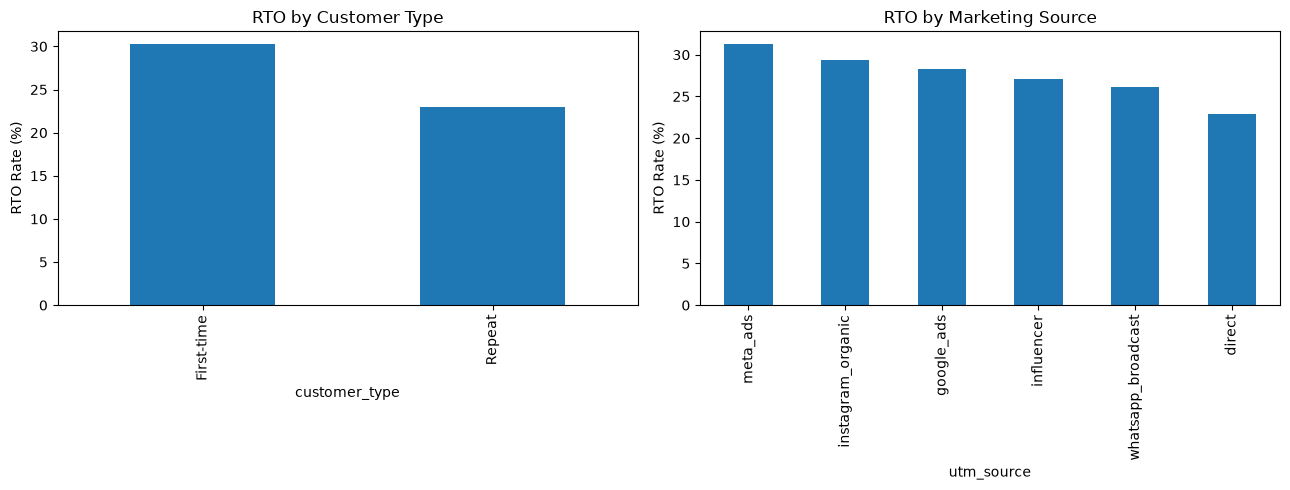

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

customer_stats["rto_rate"].plot(
    kind="bar", ax=axes[0], title="RTO by Customer Type"
)

source_analysis["rto_rate"].plot(
    kind="bar", ax=axes[1], title="RTO by Marketing Source"
)

axes[0].set_ylabel("RTO Rate (%)")
axes[1].set_ylabel("RTO Rate (%)")

plt.tight_layout()
plt.show()

In [19]:
# Features available before shipping
features = [
    "order_value",
    "customer_prior_orders",
    "customer_prior_rto",
    "city",
    "state",
    "pincode",
    "utm_source",
    "courier",
    "customer_name",
    "address"
]

X = df_clean[features].copy()
y = df_clean["is_rto"].copy()

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (1987, 10)
Target: (1987,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1589
Testing records: 398


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = [
    "order_value",
    "customer_prior_orders",
    "customer_prior_rto"
]

categorical_features = [
    "city",
    "state",
    "pincode",
    "utm_source",
    "courier",
    "customer_name",
    "address"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight="balanced"))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [24]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n", name)
    print(classification_report(y_test, predictions))

    print("ROC-AUC:", roc_auc_score(y_test, probabilities))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.80      0.80      0.80       285
           1       0.49      0.48      0.48       113

    accuracy                           0.71       398
   macro avg       0.64      0.64      0.64       398
weighted avg       0.71      0.71      0.71       398

ROC-AUC: 0.6883403198261139
Confusion Matrix:
[[229  56]
 [ 59  54]]

 Random Forest
              precision    recall  f1-score   support

           0       0.81      0.76      0.79       285
           1       0.48      0.56      0.52       113

    accuracy                           0.70       398
   macro avg       0.65      0.66      0.65       398
weighted avg       0.72      0.70      0.71       398

ROC-AUC: 0.6963359726750505
Confusion Matrix:
[[217  68]
 [ 50  63]]


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.711,0.491,0.478,0.484,0.688
1,Random Forest,0.704,0.481,0.558,0.516,0.696


In [27]:
import sys

sys.path.append("../backend")

from decision_engine import decide_order

# Test different risk probabilities
test_cases = [0.08, 0.22, 0.40, 0.82]

for risk in test_cases:

    result = decide_order(
        rto_probability=risk,
        customer_prior_orders=2
    )

    print(result)

ImportError: cannot import name 'decide_order' from 'decision_engine' (C:\Users\Zaid Nagori\OneDrive\Desktop\ml project\cod-risk-management\notebooks\../backend\decision_engine.py)

In [28]:
import sys
import importlib

sys.path.append("../backend")

import decision_engine
importlib.reload(decision_engine)

from decision_engine import decide_order

print("Decision engine imported successfully!")

Decision engine imported successfully!


In [29]:
test_cases = [0.08, 0.22, 0.40, 0.82]

for risk in test_cases:
    result = decide_order(
        rto_probability=risk,
        customer_prior_orders=2
    )
    print(result)

{'rto_probability': 8.0, 'action': 'Ship as-is', 'reason': 'Order has a low predicted RTO risk.'}
{'rto_probability': 22.0, 'action': 'Ship after confirmation', 'reason': 'Customer confirmation is recommended before shipping.'}
{'rto_probability': 40.0, 'action': 'Nudge to prepaid', 'reason': 'Offer a small discount to encourage online payment.'}
{'rto_probability': 82.0, 'action': 'Hold / cancel', 'reason': 'High predicted RTO risk. Hold for manual review before cancellation.'}


In [30]:
rto_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

decisions = []

for i, probability in enumerate(rto_probabilities):
    customer_orders = X_test.iloc[i]["customer_prior_orders"]

    result = decide_order(
        rto_probability=probability,
        customer_prior_orders=customer_orders
    )

    decisions.append(result)

decision_df = pd.DataFrame(decisions)

# Add actual order outcomes for evaluation
decision_df["actual_status"] = y_test.reset_index(drop=True).map({
    0: "DELIVERED",
    1: "RTO"
})

display(decision_df.head(10))

,rto_probability,action,reason,actual_status
0,47.96,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
1,51.80,Hold / cancel,High predicted RTO risk. Hold for manual revie...,RTO
2,49.17,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
3,48.17,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
4,49.62,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
5,50.41,Hold / cancel,High predicted RTO risk. Hold for manual revie...,DELIVERED
6,48.13,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
7,50.25,Hold / cancel,High predicted RTO risk. Hold for manual revie...,DELIVERED
8,49.11,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
9,52.92,Hold / cancel,High predicted RTO risk. Hold for manual revie...,RTO


In [31]:
print(decision_df["action"].value_counts())

action
Nudge to prepaid    267
Hold / cancel       131
Name: count, dtype: int64


Minimum risk: 0.45759851008289204
Maximum risk: 0.5452694650695592
Average risk: 0.4969861953796037

Risk distribution:
count    398.000000
mean       0.496986
std        0.016299
min        0.457599
25%        0.484590
50%        0.492278
75%        0.506423
max        0.545269
dtype: float64


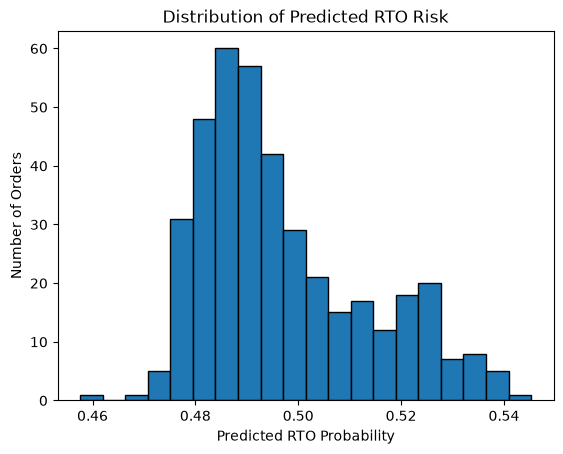

In [32]:
print("Minimum risk:", rto_probabilities.min())
print("Maximum risk:", rto_probabilities.max())
print("Average risk:", rto_probabilities.mean())

print("\nRisk distribution:")
print(pd.Series(rto_probabilities).describe())

import matplotlib.pyplot as plt

plt.hist(rto_probabilities, bins=20, edgecolor="black")
plt.xlabel("Predicted RTO Probability")
plt.ylabel("Number of Orders")
plt.title("Distribution of Predicted RTO Risk")
plt.show()

In [33]:
print("Decision thresholds:")
print(config["thresholds"])

Decision thresholds:


NameError: name 'config' is not defined

In [34]:
print("Decision thresholds:")
print(decision_engine.config["thresholds"])

Decision thresholds:
{'ship_as_is': 0.15, 'confirmation': 0.3, 'prepaid': 0.5, 'hold_cancel': 0.5}


In [35]:
print("Minimum risk:", rto_probabilities.min())
print("Maximum risk:", rto_probabilities.max())
print("Average risk:", rto_probabilities.mean())

print("\nRisk distribution:")
print(pd.Series(rto_probabilities).describe())

Minimum risk: 0.45759851008289204
Maximum risk: 0.5452694650695592
Average risk: 0.4969861953796037

Risk distribution:
count    398.000000
mean       0.496986
std        0.016299
min        0.457599
25%        0.484590
50%        0.492278
75%        0.506423
max        0.545269
dtype: float64


In [36]:
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

display(importance_df.head(15))

KeyError: 'classifier'

In [37]:
print(random_forest_model.named_steps.keys())

dict_keys(['preprocessor', 'model'])


In [38]:
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_model
    .named_steps["rf"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

display(importance_df.head(15))

KeyError: 'rf'

In [39]:
print("Pipeline steps:")
print(random_forest_model.named_steps)

print("\nAvailable step names:")
print(list(random_forest_model.named_steps.keys()))

Pipeline steps:
{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['order_value', 'customer_prior_orders',
                                  'customer_prior_rto']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['city', 'state', 'pincode', 'utm_source',
                                  'courier', 'customer_name', 'address'])]), 'model': RandomForestClassifier(class_weight='balanced', max_depth=1

In [40]:
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

display(importance_df.head(15))

,feature,importance
0,num__order_value,0.073317
31,cat__state_Uttar Pradesh,0.044455
23,cat__state_Bihar,0.042031
2693,cat__address_home,0.042000
1531,cat__address_.,0.037817
3,cat__city_Bareilly,0.037096
7,cat__city_Delhi,0.035236
2,num__customer_prior_rto,0.034276
27,cat__state_Maharashtra,0.026986
2751,cat__address_xyz,0.026021


In [41]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
is_rto
0    0.715544
1    0.284456
Name: proportion, dtype: float64

Testing target distribution:
is_rto
0    0.71608
1    0.28392
Name: proportion, dtype: float64


In [42]:
print("Payment method distribution:")
print(df_clean["payment_method"].value_counts(dropna=False))

print("\nRTO rate by payment method:")
print(
    pd.crosstab(
        df_clean["payment_method"],
        df_clean["final_status"],
        normalize="index"
    ).round(3) * 100
)

Payment method distribution:
payment_method
COD    1987
Name: count, dtype: int64

RTO rate by payment method:
final_status    DELIVERED   RTO
payment_method                 
COD                  71.6  28.4


In [43]:
import pandas as pd

# Normalize payment method values
df_clean["payment_method"] = (
    df_clean["payment_method"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Available payment methods:")
print(df_clean["payment_method"].value_counts(dropna=False))

Available payment methods:
payment_method
cod    1987
Name: count, dtype: Int64


In [44]:
cod_df = df_clean[
    df_clean["payment_method"].str.contains(
        r"\bcod\b|cash\s*on\s*delivery",
        case=False,
        na=False
    )
].copy()

print("Total COD orders:", len(cod_df))
print("\nCOD order status:")
print(cod_df["final_status"].value_counts())

Total COD orders: 1987

COD order status:
final_status
DELIVERED    1422
RTO           565
Name: count, dtype: Int64


In [45]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Select features available at order placement
numeric_features = [
    "order_value",
    "customer_prior_orders",
    "customer_prior_rto"
]

categorical_features = [
    "city",
    "state",
    "utm_source"
]

features = numeric_features + categorical_features

X = cod_df[features].copy()
y = cod_df["is_rto"].copy()

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train
random_forest_model.fit(X_train, y_train)

# Predict
y_pred = random_forest_model.predict(X_test)
rto_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate
print("MODEL PERFORMANCE")
print("-----------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1 Score:", round(f1_score(y_test, y_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, rto_probabilities), 3))

MODEL PERFORMANCE
-----------------
Accuracy: 0.658
Precision: 0.415
Recall: 0.496
F1 Score: 0.452
ROC AUC: 0.658


In [46]:
print("Minimum risk:", rto_probabilities.min())
print("Maximum risk:", rto_probabilities.max())
print("Average risk:", rto_probabilities.mean())

print("\nRisk distribution:")
print(pd.Series(rto_probabilities).describe())

Minimum risk: 0.2081599140772342
Maximum risk: 0.8269062256576857
Average risk: 0.47135556681269486

Risk distribution:
count    398.000000
mean       0.471356
std        0.119258
min        0.208160
25%        0.393407
50%        0.460634
75%        0.532433
max        0.826906
dtype: float64


In [47]:
decisions = []

for i, probability in enumerate(rto_probabilities):

    customer_orders = X_test.iloc[i]["customer_prior_orders"]

    result = decide_order(
        rto_probability=probability,
        customer_prior_orders=customer_orders
    )

    decisions.append(result)

decision_df = pd.DataFrame(decisions)

decision_df["actual_status"] = (
    y_test.reset_index(drop=True)
    .map({0: "DELIVERED", 1: "RTO"})
)

print("DECISION COUNTS")
print(decision_df["action"].value_counts())

display(decision_df.head(10))

DECISION COUNTS
action
Nudge to prepaid           240
Hold / cancel              135
Ship after confirmation     23
Name: count, dtype: int64


,rto_probability,action,reason,actual_status
0,22.39,Ship after confirmation,Customer confirmation is recommended before sh...,DELIVERED
1,36.71,Nudge to prepaid,Offer a small discount to encourage online pay...,RTO
2,40.95,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
3,46.71,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
4,47.74,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
5,48.48,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
6,39.37,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
7,47.59,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
8,43.14,Nudge to prepaid,Offer a small discount to encourage online pay...,DELIVERED
9,67.22,Hold / cancel,High predicted RTO risk. Hold for manual revie...,RTO


In [48]:
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    by="importance",
    ascending=False
)

display(importance_df.head(15))

,feature,importance
0,num__order_value,0.233240
2,num__customer_prior_rto,0.084375
1,num__customer_prior_orders,0.082623
23,cat__state_Bihar,0.069804
31,cat__state_Uttar Pradesh,0.051846
8,cat__city_Gorakhpur,0.043167
27,cat__state_Maharashtra,0.037173
37,cat__utm_source_meta_ads,0.032358
3,cat__city_Bareilly,0.027078
6,cat__city_Darbhanga,0.025132


In [49]:
import sys
sys.path.append("../backend")

from whatsapp_flow import (
    create_whatsapp_message,
    process_whatsapp_response,
    check_no_response
)

message = create_whatsapp_message(
    customer_name="Rahul",
    order_id="ORD1001",
    order_value=649
)

print(message)

Hi Rahul! 👋

Thank you for placing your order #ORD1001.

Your order value is ₹649 (Cash on Delivery).

Please confirm your order by replying:

YES - Confirm my order
NO - Cancel my order

Prefer prepaid payment?
Pay ₹629 instead of ₹649
and save ₹20!

Please reply within 24 hours.
Thank you!


In [50]:
responses = ["YES", "NO", "PREPAID", "Maybe"]

for response in responses:
    print("\nCustomer response:", response)
    print(process_whatsapp_response(response, 649))


Customer response: YES
{'status': 'CONFIRMED', 'action': 'Ship order', 'message': 'Customer confirmed the COD order.'}

Customer response: NO
{'status': 'CANCELLED', 'action': 'Cancel order', 'message': 'Customer requested cancellation.'}

Customer response: PREPAID
{'status': 'PREPAID_OFFER_ACCEPTED', 'action': 'Generate prepaid payment link', 'discounted_amount': 629, 'message': 'Customer wants to pay online.'}

Customer response: Maybe
{'status': 'MANUAL_REVIEW', 'action': 'Send to manual review', 'message': 'Customer response was unclear.'}


In [51]:
from datetime import datetime, timedelta

# Simulate a message sent 25 hours ago
sent_time = datetime.now() - timedelta(hours=25)

print(check_no_response(sent_time))

{'status': 'NO_RESPONSE', 'action': 'Hold for manual review', 'message': 'Customer did not respond within 24 hours.'}


In [52]:
import sys
sys.path.append("../backend")

from order_workflow import process_order

sample_order = {
    "order_id": "ORD1001",
    "customer_name": "Rahul",
    "order_value": 649,
    "customer_prior_orders": 1
}

result = process_order(
    order=sample_order,
    rto_probability=0.40
)

print("Decision:", result["decision"])
print("Reason:", result["reason"])
print("\nWhatsApp Message:")
print(result["whatsapp_message"])

Decision: Nudge to prepaid
Reason: Offer a small discount to encourage online payment.

WhatsApp Message:
Hi Rahul! 👋

Thank you for placing your order #ORD1001.

Your order value is ₹649 (Cash on Delivery).

Please confirm your order by replying:

YES - Confirm my order
NO - Cancel my order

Prefer prepaid payment?
Pay ₹629 instead of ₹649
and save ₹20!

Please reply within 24 hours.
Thank you!


In [53]:
for risk in [0.08, 0.22, 0.40, 0.82]:

    result = process_order(
        sample_order,
        risk
    )

    print(
        f"Risk: {risk * 100:.0f}% | "
        f"Decision: {result['decision']}"
    )

Risk: 8% | Decision: Ship as-is
Risk: 22% | Decision: Ship after confirmation
Risk: 40% | Decision: Nudge to prepaid
Risk: 82% | Decision: Hold / cancel


In [54]:
import sys
sys.path.append("../backend")

from dashboard import generate_dashboard

dashboard_data = generate_dashboard(decision_df)

for key, value in dashboard_data.items():
    print(f"{key}: {value}")

total_orders: 398
ship_as_is: 0
confirmation: 23
prepaid_nudge: 240
hold_cancel: 135
estimated_rto_savings: 9757.44
cancelled_genuine_orders: 79
estimated_lost_margin: 31788.02
net_financial_impact: -22030.58


In [55]:
import importlib
import decision_engine
import dashboard

importlib.reload(decision_engine)
importlib.reload(dashboard)

from decision_engine import decide_order
from dashboard import generate_dashboard

print(decide_order(0.82, customer_prior_orders=0))
print(decide_order(0.82, customer_prior_orders=3))

{'rto_probability': 82.0, 'action': 'Ship after confirmation', 'reason': 'High predicted RTO risk for a first-time customer. Require confirmation and manual review.'}
{'rto_probability': 82.0, 'action': 'Hold / cancel', 'reason': 'High predicted RTO risk. Hold for manual review before cancellation.'}


In [56]:
dashboard_data = generate_dashboard(decision_df)

for key, value in dashboard_data.items():
    print(f"{key}: {value}")

total_orders: 398
ship_as_is: 0
confirmation: 23
prepaid_nudge: 240
hold_cancel_manual_review: 135
estimated_rto_savings: 9757.44
estimated_discount_cost: 4800
genuine_orders_at_risk: 79
estimated_lost_margin: 31788.02
estimated_net_financial_impact: -26830.58


In [58]:
prepaid_orders = 240

RTO_COST = 169.40
COD_RTO_RATE = 0.28
PREPAID_RTO_RATE = 0.04
PREPAID_DISCOUNT = 20

for conversion_rate in [0.25, 0.50, 0.75]:

    converted_orders = prepaid_orders * conversion_rate

    savings = (
        converted_orders
        * (COD_RTO_RATE - PREPAID_RTO_RATE)
        * RTO_COST
    )

    discount_cost = converted_orders * PREPAID_DISCOUNT

    net_benefit = savings - discount_cost

    print(f"\nConversion rate: {conversion_rate * 100:.0f}%")
    print(f"Converted orders: {converted_orders:.0f}")
    print(f"RTO savings: ₹{savings:.2f}")
    print(f"Discount cost: ₹{discount_cost:.2f}")
    print(f"Net prepaid benefit: ₹{net_benefit:.2f}")


Conversion rate: 25%
Converted orders: 60
RTO savings: ₹2439.36
Discount cost: ₹1200.00
Net prepaid benefit: ₹1239.36

Conversion rate: 50%
Converted orders: 120
RTO savings: ₹4878.72
Discount cost: ₹2400.00
Net prepaid benefit: ₹2478.72

Conversion rate: 75%
Converted orders: 180
RTO savings: ₹7318.08
Discount cost: ₹3600.00
Net prepaid benefit: ₹3718.08


In [59]:
decision_df.to_csv("../data/decision_log.csv", index=False)

print("Decision log saved successfully!")

Decision log saved successfully!


In [60]:
print(
    decision_df[
        (decision_df["action"] == "Hold / cancel") &
        (decision_df["customer_prior_orders"] == 0)
    ].shape[0]
)

KeyError: 'customer_prior_orders'

In [61]:
# Add customer history back into decision_df
decision_df = decision_df.reset_index(drop=True)
decision_df["customer_prior_orders"] = X_test["customer_prior_orders"].reset_index(drop=True)

# Now check first-time customers in Hold / cancel
first_time_hold = decision_df[
    (decision_df["action"] == "Hold / cancel") &
    (decision_df["customer_prior_orders"] == 0)
]

print("First-time customers in Hold/Cancel:", len(first_time_hold))

First-time customers in Hold/Cancel: 109


In [63]:
rto_probabilities = rf_model.predict_proba(X_test)[:, 1]

NameError: name 'rf_model' is not defined

In [64]:
print("Available model variables:")

for name, obj in globals().items():
    if hasattr(obj, "predict_proba"):
        print(name, "->", type(obj).__name__)

Available model variables:


RuntimeError: dictionary changed size during iteration

In [65]:
model_variables = list(globals().items())

print("Available model variables:")

for name, obj in model_variables:
    if hasattr(obj, "predict_proba"):
        print(name, "->", type(obj).__name__)

Available model variables:
Pipeline -> ABCMeta
LogisticRegression -> type
RandomForestClassifier -> ABCMeta
logistic_model -> Pipeline
random_forest_model -> Pipeline
model -> Pipeline


In [66]:
rto_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Predictions generated:", len(rto_probabilities))

Predictions generated: 398


In [67]:
import importlib
import decision_engine
importlib.reload(decision_engine)

from decision_engine import decide_order

decisions = []

for i, probability in enumerate(rto_probabilities):
    customer_orders = X_test.iloc[i]["customer_prior_orders"]

    result = decide_order(
        rto_probability=probability,
        customer_prior_orders=customer_orders
    )

    decisions.append(result)

decision_df = pd.DataFrame(decisions)

decision_df["customer_prior_orders"] = (
    X_test["customer_prior_orders"].reset_index(drop=True)
)

decision_df["actual_status"] = (
    y_test.reset_index(drop=True)
    .map({0: "DELIVERED", 1: "RTO"})
)

print("Decision distribution:")
print(decision_df["action"].value_counts())

print(
    "First-time customers in Hold/Cancel:",
    len(decision_df[
        (decision_df["action"] == "Hold / cancel") &
        (decision_df["customer_prior_orders"] == 0)
    ])
)

Decision distribution:
action
Nudge to prepaid           240
Ship after confirmation    132
Hold / cancel               26
Name: count, dtype: int64
First-time customers in Hold/Cancel: 0


In [68]:
decision_df.to_csv("../data/decision_log.csv", index=False)

print("Updated decision log saved successfully!")

Updated decision log saved successfully!


In [70]:
decision_df.to_csv("../data/decision_log.csv", index=False)